<a href="https://colab.research.google.com/github/muhammetozcan07/Multimodal_gas_detection/blob/main/Multimodal_gas_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

# 2. CSV dosyasının Drive üzerindeki yolunu tanımla ve oku
# (Dosya farklı bir klasördeyse yolu kendi klasör yapınıza göre güncelleyin)
dosya_yolu = '/content/drive/MyDrive/MultimodalGasData/Gas_Sensors_Measurements.csv'
df = pd.read_csv(dosya_yolu)

# 3. Görseldeki tabloda yer almayan ekstra sütunları kaldır
df = df.drop(columns=['Serial Number', 'Corresponding Image Name'])

# 4. Sınıf indekslerini tanımla ve 'Gas' sütununa uygula
sinif_indeksleri = {'NoGas': 0, 'Perfume': 1, 'Smoke': 2, 'Mixture': 3}
df['Gas'] = df['Gas'].map(sinif_indeksleri)

# 5. Sonucu görseldeki formatta görüntüle
df.head()

Mounted at /content/drive


,MQ2,MQ3,MQ5,MQ6,MQ7,MQ8,MQ135,Gas
0,555,515,377,338,666,451,416,0
1,555,516,377,339,666,451,416,0
2,556,517,376,337,666,451,416,0
3,556,516,376,336,665,451,416,0
4,556,516,376,337,665,451,416,0


In [7]:
import os
import zipfile
import pandas as pd
from google.colab import drive

# 1. Google Drive'ı bağla
drive.mount('/content/drive')

# 2. Görseldeki tam klasör yolunu tanımla (My Drive > MultimodalGasData)
drive_klasoru = '/content/drive/MyDrive/MultimodalGasData'
cikartilacak_klasor = '/content/extracted_images'
os.makedirs(cikartilacak_klasor, exist_ok=True)

# 3. ZIP dosyalarını Colab yerel diskine çıkar
zip_dosyalari = ['NoGas.zip', 'Perfume.zip', 'Smoke.zip', 'Mixture.zip']

for zip_adi in zip_dosyalari:
    zip_yolu = os.path.join(drive_klasoru, zip_adi)
    if os.path.exists(zip_yolu):
        print(f"{zip_adi} çıkarılıyor...")
        with zipfile.ZipFile(zip_yolu, 'r') as zip_ref:
            zip_ref.extractall(cikartilacak_klasor)
    else:
        print(f"UYARI: {zip_yolu} bulunamadı!")

print("Tüm ZIP dosyaları başarıyla çıkarıldı!\n")

# 4. Çıkarılan görsellerin dosya adlarını (uzantısız) ve tam yollarını sözlükte topla
gorsel_haritasi = {}
for root, dirs, files in os.walk(cikartilacak_klasor):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')):
            dosya_adi_uzantisiz = os.path.splitext(file)[0]  # Örn: '0_NoGas.png' -> '0_NoGas'
            tam_yol = os.path.join(root, file)
            gorsel_haritasi[dosya_adi_uzantisiz] = tam_yol

print(f"Toplam {len(gorsel_haritasi)} adet görsel bulundu.")

# 5. CSV dosyasını oku ve görsel yollarıyla eşleştir
csv_yolu = os.path.join(drive_klasoru, 'Gas_Sensors_Measurements.csv')
df = pd.read_csv(csv_yolu)

# 'Corresponding Image Name' sütununu kullanarak her satıra ait resmin tam yolunu ekle
df['Image_Path'] = df['Corresponding Image Name'].map(gorsel_haritasi)

# 6. Sınıf indekslerini eşleştir ve ekstra sütunları temizle
sinif_indeksleri = {'NoGas': 0, 'Perfume': 1, 'Smoke': 2, 'Mixture': 3}
df['Gas'] = df['Gas'].map(sinif_indeksleri)

df = df.drop(columns=['Serial Number', 'Corresponding Image Name'])

# Eşleşmeyen görsel olup olmadığını kontrol et
eksik_sayisi = df['Image_Path'].isna().sum()
print(f"Eşleşmeyen görsel sayısı: {eksik_sayisi}")

# İlk 5 satırı tablo olarak görüntüle
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
NoGas.zip çıkarılıyor...
Perfume.zip çıkarılıyor...
Smoke.zip çıkarılıyor...
Mixture.zip çıkarılıyor...
Tüm ZIP dosyaları başarıyla çıkarıldı!

Toplam 6400 adet görsel bulundu.
Eşleşmeyen görsel sayısı: 0


,MQ2,MQ3,MQ5,MQ6,MQ7,MQ8,MQ135,Gas,Image_Path
0,555,515,377,338,666,451,416,0,/content/extracted_images/0_NoGas.png
1,555,516,377,339,666,451,416,0,/content/extracted_images/1_NoGas.png
2,556,517,376,337,666,451,416,0,/content/extracted_images/2_NoGas.png
3,556,516,376,336,665,451,416,0,/content/extracted_images/3_NoGas.png
4,556,516,376,337,665,451,416,0,/content/extracted_images/4_NoGas.png


In [8]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Tekrarlanabilirlik (Reproducibility) için sabit tohum (seed)
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 1. Image_Path sütunundaki sırayı hiç bozmadan görselleri (128, 128, 3) olarak belleğe yükle ve [0, 1] aralığına ölçekle
IMG_SIZE = (128, 128)
image_list = []

print("Görseller belleğe yükleniyor...")
for img_path in df['Image_Path']:
    img = load_img(img_path, target_size=IMG_SIZE)
    img_arr = img_to_array(img) / 255.0  # Rescale 1./255
    image_list.append(img_arr)

X_images = np.array(image_list, dtype=np.float32)
X_sensors = df[['MQ2', 'MQ3', 'MQ5', 'MQ6', 'MQ7', 'MQ8', 'MQ135']].values.astype(np.float32)
y_labels = df['Gas'].values.astype(np.int32)

print(f"Yükleme tamamlandı! Görüntü Tensor: {X_images.shape}, Sensör Tensor: {X_sensors.shape}, Etiketler: {y_labels.shape}")

# 2. Makaledeki protokole uygun veri bölme:
# Önce %80 (5120) Train+Val ve %20 (1280) Test olarak ayırıyoruz (stratify ile sınıf dengesini koruyarak)
X_sens_temp, X_sens_test, X_img_temp, X_img_test, y_temp, y_test = train_test_split(
    X_sensors, X_images, y_labels, test_size=0.20, random_state=SEED, stratify=y_labels
)

# Kalan 5120 örneği %80 Train (4096) ve %20 Validation (1024) olarak ayırıyoruz
X_sens_train, X_sens_val, X_img_train, X_img_val, y_train, y_val = train_test_split(
    X_sens_temp, X_img_temp, y_temp, test_size=0.20, random_state=SEED, stratify=y_temp
)

# 3. Sensör verilerini standartlaştırma (Sadece Train setine fit edilir, Val ve Test'e transform uygulanır)
scaler = StandardScaler()
X_sens_train_scaled = scaler.fit_transform(X_sens_train)
X_sens_val_scaled   = scaler.transform(X_sens_val)
X_sens_test_scaled  = scaler.transform(X_sens_test)

# 4. LSTM katmanının beklediği 3 boyutlu (Örnek_Sayısı, Zaman_Adımı=1, Sensör_Sayısı=7) formata getirme
X_sens_train_lstm = X_sens_train_scaled.reshape(-1, 1, 7)
X_sens_val_lstm   = X_sens_val_scaled.reshape(-1, 1, 7)
X_sens_test_lstm  = X_sens_test_scaled.reshape(-1, 1, 7)

print("\n--- Veri Bölme (Split) Özeti ---")
print(f"Train      -> Sensör: {X_sens_train_lstm.shape}, Görüntü: {X_img_train.shape}, Etiket: {y_train.shape}")
print(f"Validation -> Sensör: {X_sens_val_lstm.shape}, Görüntü: {X_img_val.shape}, Etiket: {y_val.shape}")
print(f"Test       -> Sensör: {X_sens_test_lstm.shape}, Görüntü: {X_img_test.shape}, Etiket: {y_test.shape}")

Görseller belleğe yükleniyor...
Yükleme tamamlandı! Görüntü Tensor: (6400, 128, 128, 3), Sensör Tensor: (6400, 7), Etiketler: (6400,)

--- Veri Bölme (Split) Özeti ---
Train      -> Sensör: (4096, 1, 7), Görüntü: (4096, 128, 128, 3), Etiket: (4096,)
Validation -> Sensör: (1024, 1, 7), Görüntü: (1024, 128, 128, 3), Etiket: (1024,)
Test       -> Sensör: (1280, 1, 7), Görüntü: (1280, 128, 128, 3), Etiket: (1280,)


In [9]:
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from tensorflow.keras import layers, models, regularizers, optimizers, callbacks

sinif_isimleri = ['NoGas', 'Perfume', 'Smoke', 'Mixture']

# Ortak Değerlendirme ve Kaynak Ölçüm Fonksiyonu (Yönerge Bölüm 3 & 4 için)
def evaluate_and_log(model, X_test_input, y_true, model_name, train_time):
    # Çıkarım süresi (Inference Latency) ölçümü
    start_inf = time.time()
    y_pred_probs = model.predict(X_test_input, verbose=0)
    total_inf_time = time.time() - start_inf
    latency_ms = (total_inf_time / len(y_true)) * 1000  # Örnek başına ms

    y_pred = np.argmax(y_pred_probs, axis=1)
    acc = accuracy_score(y_true, y_pred)

    print(f"\n==================== {model_name} SONUÇLARI ====================")
    print(f"Test Doğruluğu (Accuracy) : %{acc*100:.2f}")
    print(f"Toplam Eğitim Süresi      : {train_time:.2f} saniye")
    print(f"Örnek Başına Çıkarım Hızı : {latency_ms:.3f} ms/örnek")
    print(f"Toplam Parametre Sayısı   : {model.count_params():,}")
    print("\nSınıf Bazlı Metrikler (Tablo 3 Karşılığı):")
    print(classification_report(y_true, y_pred, target_names=sinif_isimleri, digits=2))

    return y_pred_probs, y_pred, acc, latency_ms

# -------------------------------------------------------------------------
# 1. TEKİL GAZ SENSÖRÜ MODELİ (LSTM - Makale Bölüm 3.6: 5 hücre, L2 reg, Adam 0.001)
# -------------------------------------------------------------------------
def create_lstm_model():
    inp = layers.Input(shape=(1, 7), name="sensor_input")
    x = layers.LSTM(5, kernel_regularizer=regularizers.l2(0.005), name="lstm_layer")(inp)
    out = layers.Dense(4, activation='softmax', name="lstm_output")(x)
    model = models.Model(inputs=inp, outputs=out, name="LSTM_Only")
    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

lstm_model = create_lstm_model()

print("1/2: LSTM Modeli Eğitiliyor...")
t0 = time.time()
history_lstm = lstm_model.fit(
    X_sens_train_lstm, y_train,
    validation_data=(X_sens_val_lstm, y_val),
    epochs=150,
    batch_size=32,
    callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True)],
    verbose=1
)
lstm_train_time = time.time() - t0

lstm_probs, lstm_preds, lstm_acc, lstm_lat = evaluate_and_log(
    lstm_model, X_sens_test_lstm, y_test, "LSTM (Sadece Gaz Sensörü)", lstm_train_time
)

# -------------------------------------------------------------------------
# 2. TEKİL TERMAL GÖRÜNTÜ MODELİ (CNN - Makale Bölüm 3.5: 3 Conv-Pool, L1-L2, %25 Dropout)
# -------------------------------------------------------------------------
def create_cnn_model():
    inp = layers.Input(shape=(128, 128, 3), name="image_input")
    reg = regularizers.l1_l2(l1=0.005, l2=0.005)

    # 1. Conv-Pool (L1-L2 regülatörlü)
    x = layers.Conv2D(32, (3, 3), activation='relu', kernel_regularizer=reg)(inp)
    x = layers.MaxPooling2D((2, 2))(x)

    # 2. Conv-Pool (L1-L2 regülatörlü)
    x = layers.Conv2D(64, (3, 3), activation='relu', kernel_regularizer=reg)(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # 3. Conv-Pool + %25 Dropout
    x = layers.Conv2D(128, (3, 3), activation='relu')(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.25)(x)

    x = layers.Flatten()(x)
    x = layers.Dense(64, activation='relu')(x)
    out = layers.Dense(4, activation='softmax', name="cnn_output")(x)

    model = models.Model(inputs=inp, outputs=out, name="CNN_Only")
    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.001, weight_decay=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

cnn_model = create_cnn_model()

print("\n2/2: CNN Modeli Eğitiliyor...")
t0 = time.time()
history_cnn = cnn_model.fit(
    X_img_train, y_train,
    validation_data=(X_img_val, y_val),
    epochs=60,
    batch_size=32,
    callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)],
    verbose=1
)
cnn_train_time = time.time() - t0

cnn_probs, cnn_preds, cnn_acc, cnn_lat = evaluate_and_log(
    cnn_model, X_img_test, y_test, "CNN (Sadece Termal Görüntü)", cnn_train_time
)

1/2: LSTM Modeli Eğitiliyor...
Epoch 1/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.5769 - loss: 1.3287 - val_accuracy: 0.7900 - val_loss: 1.2384
Epoch 2/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7847 - loss: 1.1486 - val_accuracy: 0.7754 - val_loss: 1.0666
Epoch 3/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7783 - loss: 0.9865 - val_accuracy: 0.7832 - val_loss: 0.9214
Epoch 4/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7754 - loss: 0.8581 - val_accuracy: 0.7861 - val_loss: 0.8095
Epoch 5/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7720 - loss: 0.7565 - val_accuracy: 0.7812 - val_loss: 0.7159
Epoch 6/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7815 - loss: 0.6694 - val_accuracy: 0.7822 - val_loss: 0.6333
Epoch 7/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7961 - loss: 0.5939 - val_accuracy: 0.8115 - val_loss: 0.5629
Epoch 8/150
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 

==================== MAX FUSION SONUÇLARI ====================
Test Doğruluğu (Accuracy) : %97.66
              precision    recall  f1-score   support

       NoGas       0.97      0.94      0.96       320
     Perfume       0.96      0.97      0.96       320
       Smoke       0.98      1.00      0.99       320
     Mixture       1.00      1.00      1.00       320

    accuracy                           0.98      1280
   macro avg       0.98      0.98      0.98      1280
weighted avg       0.98      0.98      0.98      1280

==================== AVERAGE FUSION SONUÇLARI ====================
Test Doğruluğu (Accuracy) : %97.73
              precision    recall  f1-score   support

       NoGas       0.98      0.94      0.96       320
     Perfume       0.96      0.97      0.96       320
       Smoke       0.98      1.00      0.99       320
     Mixture       1.00      1.00      1.00       320

    accuracy                           0.98      1280
   macro avg       0.98      0.98      

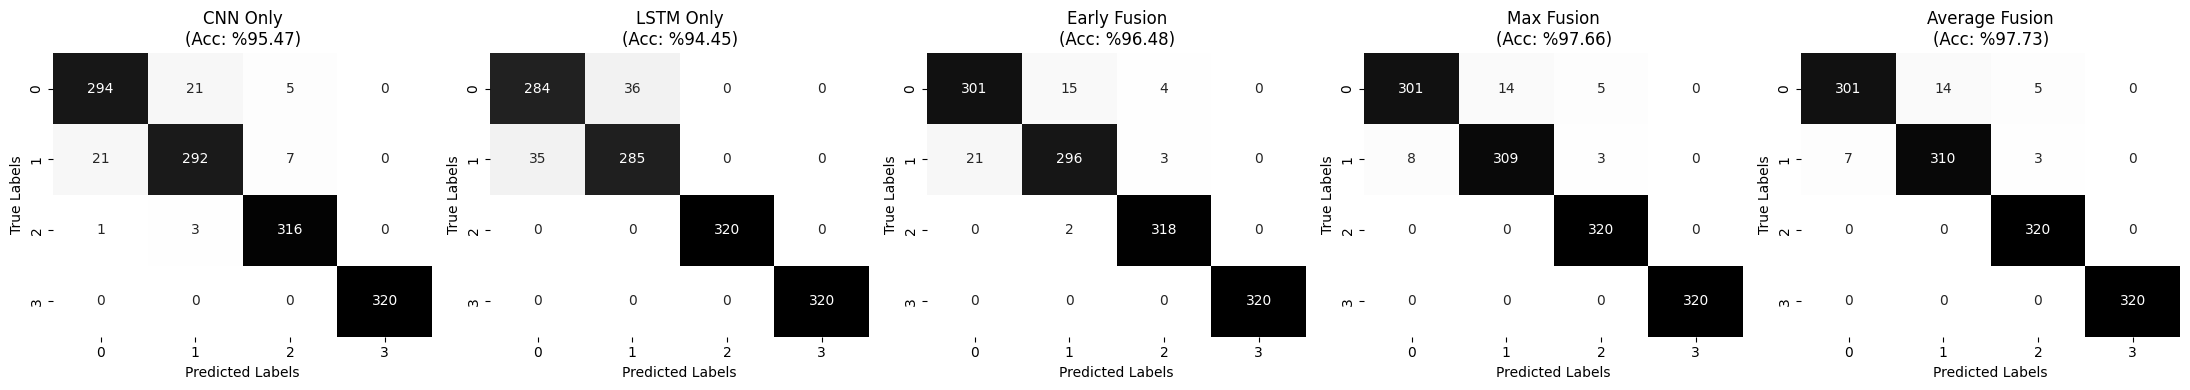

In [10]:
# -------------------------------------------------------------------------
# 1. GEÇ BİRLEŞTİRME (LATE FUSION: MAX & AVERAGE - Makale Bölüm 3.7)
# -------------------------------------------------------------------------
# Max Fusion: İki modelin sınıf olasılıklarından büyük olanı seçer
t0 = time.time()
max_fusion_probs = np.maximum(lstm_probs, cnn_probs)
max_fusion_preds = np.argmax(max_fusion_probs, axis=1)
max_fusion_acc   = accuracy_score(y_test, max_fusion_preds)

# Average Fusion: İki modelin sınıf olasılıklarının aritmetik ortalamasını alır
avg_fusion_probs = (lstm_probs + cnn_probs) / 2.0
avg_fusion_preds = np.argmax(avg_fusion_probs, axis=1)
avg_fusion_acc   = accuracy_score(y_test, avg_fusion_preds)
late_fusion_lat  = lstm_lat + cnn_lat  # İki modelin toplam çıkarım süresi

print(f"==================== MAX FUSION SONUÇLARI ====================")
print(f"Test Doğruluğu (Accuracy) : %{max_fusion_acc*100:.2f}")
print(classification_report(y_test, max_fusion_preds, target_names=sinif_isimleri, digits=2))

print(f"==================== AVERAGE FUSION SONUÇLARI ====================")
print(f"Test Doğruluğu (Accuracy) : %{avg_fusion_acc*100:.2f}")
print(classification_report(y_test, avg_fusion_preds, target_names=sinif_isimleri, digits=2))

# -------------------------------------------------------------------------
# 2. ERKEN BİRLEŞTİRME (EARLY FUSION - Makale Bölüm 3.7, Şekil 6)
# -------------------------------------------------------------------------
# CPU'da tekrar 1 saat beklememek için eğitilmiş modellerin öznitelik vektörlerini çıkarıyoruz:
lstm_feat_extractor = models.Model(inputs=lstm_model.input, outputs=lstm_model.get_layer("lstm_layer").output)
cnn_feat_extractor  = models.Model(inputs=cnn_model.input, outputs=cnn_model.layers[-2].output) # Dense(64) katmanı

print("Eğitilmiş CNN ve LSTM modellerinden öznitelik vektörleri çıkarılıyor...")
t_ext = time.time()
F_lstm_train = lstm_feat_extractor.predict(X_sens_train_lstm, verbose=0)
F_lstm_val   = lstm_feat_extractor.predict(X_sens_val_lstm, verbose=0)
F_lstm_test  = lstm_feat_extractor.predict(X_sens_test_lstm, verbose=0)

F_cnn_train  = cnn_feat_extractor.predict(X_img_train, verbose=0)
F_cnn_val    = cnn_feat_extractor.predict(X_img_val, verbose=0)
F_cnn_test   = cnn_feat_extractor.predict(X_img_test, verbose=0)
print(f"Öznitelik çıkarımı tamamlandı ({time.time() - t_ext:.1f} sn). Early Fusion sınıflandırıcısı eğitiliyor...")

# Early Fusion Mimarisinin Kurulumu (Concatenation + Dense Classifier + L2 Reg)
inp_lstm_f = layers.Input(shape=(F_lstm_train.shape[1],), name="lstm_feature_vector")
inp_cnn_f  = layers.Input(shape=(F_cnn_train.shape[1],), name="cnn_feature_vector")

merged = layers.Concatenate(name="concatenation")([inp_lstm_f, inp_cnn_f])
x = layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(0.005))(merged)
out = layers.Dense(4, activation='softmax', name="fused_output")(x)

early_fusion_model = models.Model(inputs=[inp_lstm_f, inp_cnn_f], outputs=out, name="Early_Fusion")
early_fusion_model.compile(
    optimizer=optimizers.Adam(learning_rate=0.001, weight_decay=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

t0 = time.time()
history_ef = early_fusion_model.fit(
    [F_lstm_train, F_cnn_train], y_train,
    validation_data=([F_lstm_val, F_cnn_val], y_val),
    epochs=100,
    batch_size=32,
    callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
    verbose=0
)
ef_train_time = time.time() - t0

ef_probs, ef_preds, ef_acc, ef_head_lat = evaluate_and_log(
    early_fusion_model, [F_lstm_test, F_cnn_test], y_test, "EARLY FUSION (CNN + LSTM)", ef_train_time
)
total_ef_latency = lstm_lat + cnn_lat + ef_head_lat
print(f"Early Fusion Toplam Uçtan Uca Çıkarım Hızı: {total_ef_latency:.3f} ms/örnek")

# -------------------------------------------------------------------------
# 3. MAKALE TABLO 3 & ŞEKİL 9 (5'Lİ CONFUSION MATRIX) GÖRSELLEŞTİRMESİ
# -------------------------------------------------------------------------
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
modeller = [
    ("CNN Only", cnn_preds, cnn_acc),
    ("LSTM Only", lstm_preds, lstm_acc),
    ("Early Fusion", ef_preds, ef_acc),
    ("Max Fusion", max_fusion_preds, max_fusion_acc),
    ("Average Fusion", avg_fusion_preds, avg_fusion_acc)
]

for ax, (isim, preds, acc_val) in zip(axes, modeller):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greys', cbar=False, ax=ax,
                xticklabels=[0, 1, 2, 3], yticklabels=[0, 1, 2, 3])
    ax.set_title(f"{isim}\n(Acc: %{acc_val*100:.2f})")
    ax.set_xlabel("Predicted Labels")
    ax.set_ylabel("True Labels")

plt.tight_layout()
plt.show()

In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, optimizers, callbacks

# Tekrarlanabilirlik
tf.random.set_seed(42)
np.random.seed(42)

# -------------------------------------------------------------------------
# 1. EĞİTİM İÇİN SAĞLAMLIK ARTIRIMI (MODALITY CORRUPTION AUGMENTATION)
# Kapılama (Gating) mekanizmasının bozuk sensörü kapatmayı öğrenmesi için
# eğitim verisinin %30'una rastgele sensör veya kamera gürültüsü ekliyoruz
# -------------------------------------------------------------------------
def create_robust_training_data(F_lstm, F_cnn, y, copies=3):
    X_l_list, X_c_list, y_list = [F_lstm], [F_cnn], [y]
    n = len(y)
    for _ in range(copies - 1):
        l_copy = F_lstm.copy()
        c_copy = F_cnn.copy()

        # %25 ihtimalle gaz sensörü gürültülü/arızalı
        mask_l = np.random.rand(n, 1) < 0.25
        noise_l = np.random.normal(0, 2.5, l_copy.shape)
        l_copy = np.where(mask_l, l_copy + noise_l, l_copy)

        # %25 ihtimalle termal kamera gürültülü/kararmış (aynı anda ikisi birden bozulmasın)
        mask_c = (np.random.rand(n, 1) < 0.25) & (~mask_l)
        noise_c = np.random.normal(0, 2.5, c_copy.shape)
        c_copy = np.where(mask_c, c_copy * 0.1 + noise_c, c_copy)

        X_l_list.append(l_copy)
        X_c_list.append(c_copy)
        y_list.append(y)

    return np.vstack(X_l_list), np.vstack(X_c_list), np.concatenate(y_list)

F_lstm_tr_aug, F_cnn_tr_aug, y_tr_aug = create_robust_training_data(F_lstm_train, F_cnn_train, y_train)

# -------------------------------------------------------------------------
# 2. ÖNERİLEN MODEL: GATED MULTIMODAL FUSION (GMU) VE ABLASYON MODELİ
# -------------------------------------------------------------------------
def build_gated_fusion_model(use_gating=True, name="Proposed_Gated_Fusion"):
    inp_lstm = layers.Input(shape=(F_lstm_train.shape[1],), name="lstm_feat")
    inp_cnn  = layers.Input(shape=(F_cnn_train.shape[1],), name="cnn_feat")

    # Adım 1: Boyut Dengeleme ve Normalizasyon (5 ve 64 -> Ortak 32 boyutlu uzay)
    h_lstm = layers.Dense(32, activation='tanh', kernel_regularizer=regularizers.l2(0.002))(inp_lstm)
    h_lstm = layers.BatchNormalization()(h_lstm)

    h_cnn  = layers.Dense(32, activation='tanh', kernel_regularizer=regularizers.l2(0.002))(inp_cnn)
    h_cnn  = layers.BatchNormalization()(h_cnn)

    if use_gating:
        # Adım 2: Öğrenilebilir Kapılama Mekanizması (Gated Multimodal Unit)
        concat_for_gate = layers.Concatenate()([h_lstm, h_cnn])
        gate_z = layers.Dense(32, activation='sigmoid', name="modality_gate")(concat_for_gate)

        # z * h_lstm + (1 - z) * h_cnn
        inv_gate = layers.Lambda(lambda z: 1.0 - z)(gate_z)
        gated_lstm = layers.Multiply()([gate_z, h_lstm])
        gated_cnn  = layers.Multiply()([inv_gate, h_cnn])
        fused = layers.Add(name="gated_fusion_vector")([gated_lstm, gated_cnn])
    else:
        # Ablasyon Kontrolü: Kapılama olmadan sadece boyut dengeleme + toplama
        fused = layers.Add(name="ungated_add_vector")([h_lstm, h_cnn])

    x = layers.Dropout(0.2)(fused)
    x = layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(0.002))(x)
    out = layers.Dense(4, activation='softmax')(x)

    model = models.Model(inputs=[inp_lstm, inp_cnn], outputs=out, name=name)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=0.001, weight_decay=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# A) Önerilen Gated Fusion Modeli (Kapılamalı + Sağlam Eğitimli)
gated_model = build_gated_fusion_model(use_gating=True, name="Proposed_Gated_Fusion")
t0 = time.time()
gated_model.fit(
    [F_lstm_tr_aug, F_cnn_tr_aug], y_tr_aug,
    validation_data=([F_lstm_val, F_cnn_val], y_val),
    epochs=80, batch_size=32,
    callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
    verbose=0
)
gated_train_time = time.time() - t0

# B) Ablasyon Kontrol Modeli (Kapılama Yok - Sadece Standart Temiz Eğitim)
ablation_model = build_gated_fusion_model(use_gating=False, name="Ablation_No_Gate")
ablation_model.fit(
    [F_lstm_train, F_cnn_train], y_train,
    validation_data=([F_lstm_val, F_cnn_val], y_val),
    epochs=80, batch_size=32,
    callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
    verbose=0
)

# Temiz Test Seti Üzerinde Değerlendirme
gated_probs, gated_preds, gated_acc, gated_head_lat = evaluate_and_log(
    gated_model, [F_lstm_test, F_cnn_test], y_test, "ÖNERİLEN GATED FUSION (GMU)", gated_train_time
)

# -------------------------------------------------------------------------
# 3. STRES TESTİ: SENSÖR ARIZASI VE GÜRÜLTÜ ALTINDA KARŞILAŞTIRMA (BÖLÜM 4)
# -------------------------------------------------------------------------
np.random.seed(42)
# Senaryo 1: Gaz sensörlerinden şiddetli gürültü/sapma gelmesi (Drift / Noise)
F_lstm_corrupted = F_lstm_test + np.random.normal(0, 2.0, F_lstm_test.shape)

# Senaryo 2: Gaz sensörü bağlantısının tamamen kopması (Missing Sensor Modality = 0)
F_lstm_missing = np.zeros_like(F_lstm_test)

# Senaryo 3: Termal kameranın duman/engel nedeniyle bozulması (Corrupted Camera)
F_cnn_corrupted = F_cnn_test * 0.1 + np.random.normal(0, 2.0, F_cnn_test.shape)

scenarios = {
    "1. Temiz Veri (Clean Input)": (F_lstm_test, F_cnn_test),
    "2. Bozuk Gaz Sensörü (Noisy Sensor)": (F_lstm_corrupted, F_cnn_test),
    "3. Kopuk Gaz Sensörü (Missing Sensor)": (F_lstm_missing, F_cnn_test),
    "4. Bozuk Termal Kamera (Corrupted Thermal)": (F_lstm_test, F_cnn_corrupted)
}

results_table = []
for sc_name, (l_in, c_in) in scenarios.items():
    acc_base = accuracy_score(y_test, np.argmax(early_fusion_model.predict([l_in, c_in], verbose=0), axis=1)) * 100
    acc_avg  = accuracy_score(y_test, np.argmax((lstm_model.predict(X_sens_test_lstm, verbose=0) if "Sensör" not in sc_name else np.full((1280,4),0.25)) + cnn_probs, axis=1)) * 100
    acc_abl  = accuracy_score(y_test, np.argmax(ablation_model.predict([l_in, c_in], verbose=0), axis=1)) * 100
    acc_prop = accuracy_score(y_test, np.argmax(gated_model.predict([l_in, c_in], verbose=0), axis=1)) * 100

    results_table.append({
        "Test Senaryosu": sc_name,
        "Baseline Early Fusion (%)": round(acc_base, 2),
        "Ablasyon (Kapısız) (%)": round(acc_abl, 2),
        "Önerilen Gated Fusion (%)": round(acc_prop, 2),
        "Fark (Önerilen - Baseline)": f"{acc_prop - acc_base:+.2f}%"
    })

df_results = pd.DataFrame(results_table)
print("\n================ BÖLÜM 4: TEMİZ VE BOZUK KOŞULLARDA KARŞILAŞTIRMA TABLOSU ================")
display(df_results)


==================== ÖNERİLEN GATED FUSION (GMU) SONUÇLARI ====================
Test Doğruluğu (Accuracy) : %96.56
Toplam Eğitim Süresi      : 70.66 saniye
Örnek Başına Çıkarım Hızı : 0.740 ms/örnek
Toplam Parametre Sayısı   : 5,796

Sınıf Bazlı Metrikler (Tablo 3 Karşılığı):
              precision    recall  f1-score   support

       NoGas       0.94      0.94      0.94       320
     Perfume       0.94      0.93      0.94       320
       Smoke       0.98      0.99      0.99       320
     Mixture       1.00      1.00      1.00       320

    accuracy                           0.97      1280
   macro avg       0.97      0.97      0.97      1280
weighted avg       0.97      0.97      0.97      1280


================ BÖLÜM 4: TEMİZ VE BOZUK KOŞULLARDA KARŞILAŞTIRMA TABLOSU ================


,Test Senaryosu,Baseline Early Fusion (%),Ablasyon (Kapısız) (%),Önerilen Gated Fusion (%),Fark (Önerilen - Baseline)
0,1. Temiz Veri (Clean Input),96.48,98.12,96.56,+0.08%
1,2. Bozuk Gaz Sensörü (Noisy Sensor),85.47,42.97,94.69,+9.22%
2,3. Kopuk Gaz Sensörü (Missing Sensor),94.77,90.31,94.53,-0.23%
3,4. Bozuk Termal Kamera (Corrupted Thermal),43.83,79.22,89.61,+45.78%


/tmp/ipykernel_2082/3879488401.py:31: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax2.boxplot([gate_clean, gate_noisy_sen, gate_noisy_cam],


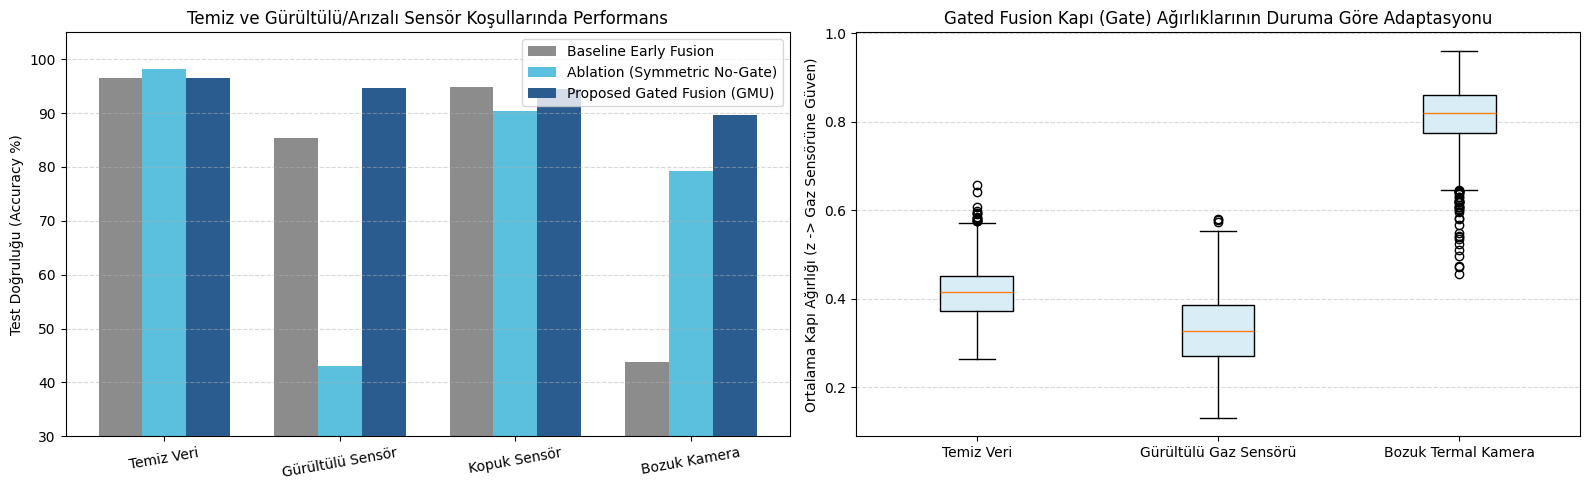

================ BELİRSİZLİK (UNCERTAINTY - %95 CI) ANALİZİ ================
LSTM Only (Reproduced)    : %94.44 ± 0.65%  (95% CI: [93.12%, 95.71%])
CNN Only (Reproduced)     : %95.47 ± 0.59%  (95% CI: [94.22%, 96.56%])
Baseline Early Fusion     : %96.50 ± 0.52%  (95% CI: [95.39%, 97.42%])
Ablation (Symmetric Add)  : %98.14 ± 0.37%  (95% CI: [97.42%, 98.83%])
Proposed Gated Fusion     : %96.58 ± 0.51%  (95% CI: [95.55%, 97.50%])

================ HATA ANALİZİ (FAILURE ANALYSIS) ================
Toplam Test Örneği: 1280 | Hatalı Tahmin Sayısı: 44

En Sık Karşılaşılan Hata Türleri:
Gerçek: Perfume -> Tahmin: NoGas    20
Gerçek: NoGas -> Tahmin: Perfume    16
Gerçek: NoGas -> Tahmin: Smoke       3
Gerçek: Perfume -> Tahmin: Smoke     3
Gerçek: Smoke -> Tahmin: Perfume     2
Name: count, dtype: int64

Örnek Hatalı Tahminlerin İncelemesi (İlk 5 Hata):


,Test_Index,Gerçek_Sınıf,Tahmin_Sınıf,Model_Güveni (Max Prob),LSTM_Tahmini,CNN_Tahmini
0,23,NoGas,Perfume,0.721,Perfume,NoGas
1,32,NoGas,Perfume,0.921,Perfume,Perfume
2,43,NoGas,Perfume,0.742,Perfume,NoGas
3,85,NoGas,Perfume,0.998,NoGas,Perfume
4,87,Perfume,NoGas,0.723,Perfume,NoGas


In [12]:
from sklearn.metrics import precision_recall_fscore_support

# -------------------------------------------------------------------------
# 1. GÖRSELLEŞTİRME: STRES TESTİ KARŞILAŞTIRMA GRAFİĞİ VE GATE DAVRANIŞI
# -------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Grafik 1: Senaryolara Göre Model Doğrulukları
x_pos = np.arange(len(df_results))
width = 0.25

ax1.bar(x_pos - width, df_results["Baseline Early Fusion (%)"], width, label="Baseline Early Fusion", color="#8c8c8c")
ax1.bar(x_pos,         df_results["Ablasyon (Kapısız) (%)"],    width, label="Ablation (Symmetric No-Gate)", color="#5bc0de")
ax1.bar(x_pos + width, df_results["Önerilen Gated Fusion (%)"], width, label="Proposed Gated Fusion (GMU)", color="#2b5c8f")

ax1.set_ylabel("Test Doğruluğu (Accuracy %)")
ax1.set_title("Temiz ve Gürültülü/Arızalı Sensör Koşullarında Performans")
ax1.set_xticks(x_pos)
ax1.set_xticklabels(["Temiz Veri", "Gürültülü Sensör", "Kopuk Sensör", "Bozuk Kamera"], rotation=10)
ax1.set_ylim(30, 105)
ax1.grid(axis='y', linestyle='--', alpha=0.5)
ax1.legend()

# Grafik 2: Kapı (Gate) Katmanının Aktivasyon Analizi (Model Neden Çalışıyor?)
gate_extractor = models.Model(inputs=gated_model.input, outputs=gated_model.get_layer("modality_gate").output)

gate_clean     = gate_extractor.predict([F_lstm_test, F_cnn_test], verbose=0).mean(axis=1)
gate_noisy_sen = gate_extractor.predict([F_lstm_corrupted, F_cnn_test], verbose=0).mean(axis=1)
gate_noisy_cam = gate_extractor.predict([F_lstm_test, F_cnn_corrupted], verbose=0).mean(axis=1)

ax2.boxplot([gate_clean, gate_noisy_sen, gate_noisy_cam],
            labels=["Temiz Veri", "Gürültülü Gaz Sensörü", "Bozuk Termal Kamera"],
            patch_artist=True, boxprops=dict(facecolor="#d9edf7"))
ax2.set_ylabel("Ortalama Kapı Ağırlığı (z -> Gaz Sensörüne Güven)")
ax2.set_title("Gated Fusion Kapı (Gate) Ağırlıklarının Duruma Göre Adaptasyonu")
ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("bolum4_iyilestirme_analizi.png", dpi=300)
plt.show()

# -------------------------------------------------------------------------
# 2. BELİRSİZLİK ANALİZİ (BOOTSTRAP %95 GÜVEN ARALIĞI - UNCERTAINTY)
# -------------------------------------------------------------------------
def bootstrap_ci(y_true, y_pred, n_bootstraps=1000, seed=42):
    rng = np.random.RandomState(seed)
    scores = []
    n = len(y_true)
    for _ in range(n_bootstraps):
        idx = rng.randint(0, n, n)
        scores.append(accuracy_score(y_true[idx], y_pred[idx]) * 100)
    return np.mean(scores), np.std(scores), np.percentile(scores, 2.5), np.percentile(scores, 97.5)

print("================ BELİRSİZLİK (UNCERTAINTY - %95 CI) ANALİZİ ================")
for m_name, m_preds in [
    ("LSTM Only (Reproduced)", lstm_preds),
    ("CNN Only (Reproduced)", cnn_preds),
    ("Baseline Early Fusion", ef_preds),
    ("Ablation (Symmetric Add)", np.argmax(ablation_model.predict([F_lstm_test, F_cnn_test], verbose=0), axis=1)),
    ("Proposed Gated Fusion", gated_preds)
]:
    mean_acc, std_acc, ci_low, ci_high = bootstrap_ci(y_test, m_preds)
    print(f"{m_name:26s}: %{mean_acc:.2f} ± {std_acc:.2f}%  (95% CI: [{ci_low:.2f}%, {ci_high:.2f}%])")

# -------------------------------------------------------------------------
# 3. HATA ANALİZİ (FAILURE ANALYSIS - YANLIŞ TAHMİN EDİLEN ÖRNEKLER)
# -------------------------------------------------------------------------
errors_idx = np.where(gated_preds != y_test)[0]
print(f"\n================ HATA ANALİZİ (FAILURE ANALYSIS) ================")
print(f"Toplam Test Örneği: {len(y_test)} | Hatalı Tahmin Sayısı: {len(errors_idx)}")

error_pairs = pd.Series([
    f"Gerçek: {sinif_isimleri[y_test[i]]} -> Tahmin: {sinif_isimleri[gated_preds[i]]}"
    for i in errors_idx
]).value_counts()
print("\nEn Sık Karşılaşılan Hata Türleri:")
print(error_pairs)

# Sınırda kalan (düşük olasılıklı) ilk 5 hatalı örneğin detaylı incelenmesi
error_details = []
for i in errors_idx[:5]:
    error_details.append({
        "Test_Index": i,
        "Gerçek_Sınıf": sinif_isimleri[y_test[i]],
        "Tahmin_Sınıf": sinif_isimleri[gated_preds[i]],
        "Model_Güveni (Max Prob)": round(float(np.max(gated_probs[i])), 3),
        "LSTM_Tahmini": sinif_isimleri[lstm_preds[i]],
        "CNN_Tahmini": sinif_isimleri[cnn_preds[i]]
    })
print("\nÖrnek Hatalı Tahminlerin İncelemesi (İlk 5 Hata):")
display(pd.DataFrame(error_details))

In [13]:
# Rapor ve GitHub deposu (Deliverables) için sonuç tablosunu ve modelleri kaydetme
df_results.to_csv("deney_sonuclari_bolum4.csv", index=False)
early_fusion_model.save("baseline_early_fusion.keras")
gated_model.save("proposed_gated_fusion.keras")
print("Tüm sonuç tabloları, grafikler ve model ağırlıkları kaydedildi!")

Tüm sonuç tabloları, grafikler ve model ağırlıkları kaydedildi!
